# 02 · Préparation : fenêtres, découpage temporel, export

**Date :** 2 novembre 2026 (code simplifié le 3 novembre ; découpage en 3 parties le 4 novembre 2026)

**Ce qui est fait :**
1. Ajout de 4 caractéristiques de fenêtre par IP source et par minute : `w_conn`, `w_dst_ports`, `w_dst_hosts`, `w_rst_rate`.
2. Découpage de lun, mar, mer **temporel par classe** en 3 parties : pour chaque attaque, ses 70 % de flux les plus anciens en train, les 15 % suivants en val, les 15 % les plus récents en test_connu. Le benign suit la même règle dans chaque jour. test_inconnu = jeu + ven en entier.
3. Retrait des caractéristiques constantes sur train.
4. Contrôles, puis export dans `data/processed/{train,val,test_connu,test_inconnu}.parquet` + `features.json`.

**Pourquoi :**
- Les fenêtres rendent visible un comportement réparti sur plusieurs flux (scan, force brute) même quand on regarde un seul flux.
- La val sert à choisir les réglages : les scores qu'on y mesure sont donc un peu optimistes. Et LYCOS ne rejoue aucune attaque un autre jour, donc jeu + ven ne contiennent que des attaques inconnues. Le **test connu** donne une mesure finale des attaques connues sur des flux jamais utilisés pour choisir un réglage.
- Le découpage reste temporel (aucun mélange aléatoire) : dans chaque groupe, val vient après train et test_connu vient après val.

**Limite :** test_connu vient du même jour que le train, juste après lui. C'est donc plus facile qu'une attaque rejouée un autre jour.

**Heartbleed** n'a que 11 flux au total, donc très peu en val et en test_connu : on le garde, mais ses chiffres ne sont pas fiables.

Aucun scaler ici : il sera ajusté sur train dans les notebooks 03 et 04 (règle 7).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent / "src"))
from isocrates.ml.data import ID_COLS, LABEL, BENIGN, TS, ROOT, feature_columns, read_header
from isocrates.ml.prepare import (WINDOW_COLS, TRAIN_FRAC, VAL_FRAC, load_with_windows, temporal_split,
                                  split_groups, constant_columns, model_features, save_split)

REPORTS = ROOT / "reports"
OUT = ROOT / "data" / "processed"
sns.set_theme(style="whitegrid")

train_days = ["lun", "mar", "mer"]
test_days = ["jeu", "ven"]


def to_local_time(timestamp):
    """Convertit un timestamp (µs, UTC) en heure locale du banc d'essai (UTC-3 en juillet)."""
    utc_time = pd.to_datetime(timestamp, unit="us", utc=True)
    return utc_time.tz_convert("America/Halifax")

## 1. Chargement de lun, mar, mer + caractéristiques de fenêtre

Fenêtres **fixes** de 60 s (une minute de l'horloge), calculées dans chaque jour séparément, à partir de `src_addr`, `dst_port`, `dst_addr` et `flag_rst` (qui vaut 0 ou 1). Les IP servent ici à regrouper les flux, jamais comme caractéristiques (règle 4).

In [2]:
known_days = load_with_windows(train_days)
print(len(known_days), "flux,", known_days.shape[1], "colonnes,", round(known_days.memory_usage(deep=True).sum() / 1e9, 2), "Go en mémoire")

# Valeur médiane des fenêtres pour chaque classe
known_days.groupby(LABEL, observed=True)[WINDOW_COLS].median().sort_values("w_conn")

1182055 flux, 88 colonnes, 0.53 Go en mémoire


,w_conn,w_dst_ports,w_dst_hosts,w_rst_rate
label,,,,
heartbleed,1.0,1.0,1.0,0.000000
ssh_patator,50.0,1.0,1.0,0.000000
ftp_patator,66.0,1.0,1.0,0.000000
benign,247.0,4.0,35.0,0.001195
dos_slowloris,265.0,1.0,1.0,0.328767
dos_slowhttptest,1008.0,1.0,1.0,0.039683
dos_goldeneye,1212.0,1.0,1.0,0.004125
dos_hulk,9688.0,1.0,1.0,0.000000


## 2. Découpage temporel par classe : 70 / 15 / 15

In [3]:
known_days = temporal_split(known_days)

counts = pd.crosstab(known_days[LABEL], known_days["split"])
counts = counts[["train", "val", "test_connu"]]
counts.sort_values("train", ascending=False)

split,train,val,test_connu
label,,,
benign,699151,149818,149820
dos_hulk,111291,23848,23849
dos_goldeneye,4735,1015,1015
dos_slowloris,3971,851,852
dos_slowhttptest,3406,730,730
ftp_patator,2802,600,601
ssh_patator,2071,444,444
heartbleed,7,2,2


In [4]:
# Vérification : dans chaque groupe, val doit venir APRÈS train et test_connu APRÈS val
group = split_groups(known_days)

check_rows = []
for name in group.unique():
    rows = known_days[group == name]
    last_train = rows.loc[rows["split"] == "train", TS].max()
    first_val = rows.loc[rows["split"] == "val", TS].min()
    last_val = rows.loc[rows["split"] == "val", TS].max()
    first_test = rows.loc[rows["split"] == "test_connu", TS].min()

    assert first_val >= last_train, name
    assert first_test >= last_val, name

    check_rows.append({
        "groupe": name,
        "fin train": to_local_time(last_train).strftime("%a %H:%M:%S"),
        "début val": to_local_time(first_val).strftime("%a %H:%M:%S"),
        "fin val": to_local_time(last_val).strftime("%a %H:%M:%S"),
        "début test_connu": to_local_time(first_test).strftime("%a %H:%M:%S"),
    })

print("Garantie temporelle vérifiée pour", len(check_rows), "groupes")
pd.DataFrame(check_rows).set_index("groupe")

Garantie temporelle vérifiée pour 10 groupes


,fin train,début val,fin val,début test_connu
groupe,,,,
benign_lun,Mon 14:13:22,Mon 14:13:22,Mon 15:49:25,Mon 15:49:25
benign_mar,Tue 14:39:37,Tue 14:39:37,Tue 15:57:17,Tue 15:57:17
ftp_patator,Tue 10:02:02,Tue 10:02:02,Tue 10:11:13,Tue 10:11:14
ssh_patator,Tue 14:51:56,Tue 14:51:56,Tue 15:01:07,Tue 15:01:08
benign_mer,Wed 14:37:33,Wed 14:37:33,Wed 15:33:33,Wed 15:33:33
dos_slowloris,Wed 10:03:12,Wed 10:03:13,Wed 10:06:29,Wed 10:06:31
dos_slowhttptest,Wed 10:26:03,Wed 10:26:03,Wed 10:33:29,Wed 10:33:29
dos_hulk,Wed 10:55:37,Wed 10:55:37,Wed 10:58:09,Wed 10:58:09
dos_goldeneye,Wed 11:17:32,Wed 11:17:32,Wed 11:18:16,Wed 11:18:16


## 3. Caractéristiques constantes (décidées sur train uniquement)

In [5]:
train_part = known_days[known_days["split"] == "train"]
candidates = feature_columns(read_header()) + WINDOW_COLS
dropped = constant_columns(train_part, candidates)
features = model_features(dropped)

print("Retirées (constantes sur train) :", dropped)
print(len(features), "caractéristiques finales, dont les fenêtres :", WINDOW_COLS)

Retirées (constantes sur train) : ['flag_urg', 'fwd_flag_urg', 'bwd_flag_urg']
78 caractéristiques finales, dont les fenêtres : ['w_conn', 'w_dst_ports', 'w_dst_hosts', 'w_rst_rate']


## 4. test_inconnu : jeu + ven (mêmes traitements, rien n'est ajusté dessus)

In [6]:
test_inconnu = load_with_windows(test_days)
test_inconnu["split"] = "test_inconnu"
print(len(test_inconnu), "flux dans test_inconnu")
test_inconnu.groupby(LABEL, observed=True)[WINDOW_COLS].median().sort_values("w_conn")

655443 flux dans test_inconnu


,w_conn,w_dst_ports,w_dst_hosts,w_rst_rate
label,,,,
webattack_sql_injection,4.0,1.0,1.0,0.000000
bot,19.0,4.0,5.0,0.000000
webattack_bruteforce,35.0,1.0,1.0,0.000000
webattack_xss,35.0,1.0,1.0,0.000000
benign,248.0,4.0,32.0,0.001754
ddos,4903.0,1.0,1.0,0.000000
portscan,43868.0,997.0,1.0,0.993937


## 5. Les fenêtres séparent-elles les classes ?

Pour le graphique seulement, on prend au plus 5 000 flux par classe (tirage avec graine fixe).

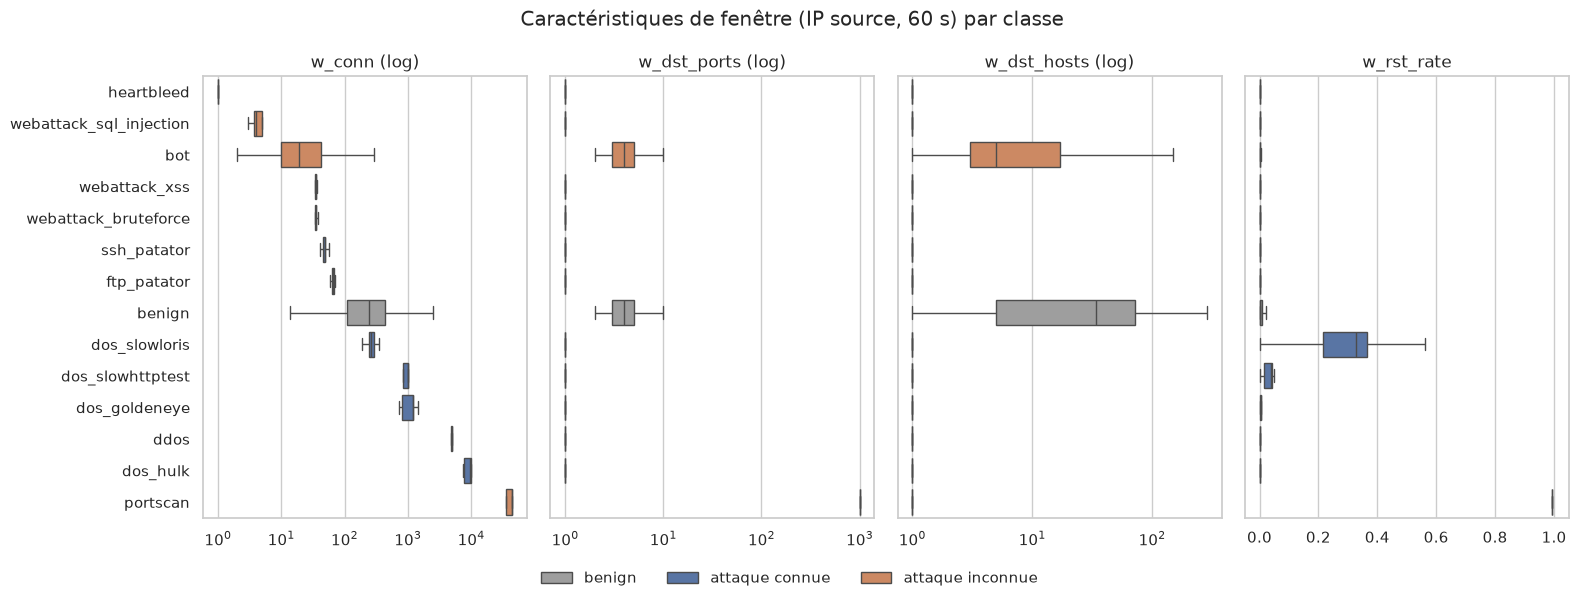

In [7]:
all_flows = pd.concat([known_days[[LABEL] + WINDOW_COLS], test_inconnu[[LABEL] + WINDOW_COLS]], ignore_index=True)
all_flows[LABEL] = all_flows[LABEL].astype(str)

# Échantillon : au plus 5 000 flux par classe
pieces = []
for name in all_flows[LABEL].unique():
    one_class = all_flows[all_flows[LABEL] == name]
    n = min(len(one_class), 5000)
    pieces.append(one_class.sample(n, random_state=0))
sample = pd.concat(pieces)

# Type de chaque classe, pour choisir la couleur
test_attacks = set(test_inconnu[LABEL].astype(str)) - {BENIGN}
kind_of = {}
for name in sample[LABEL].unique():
    if name == BENIGN:
        kind_of[name] = "benign"
    elif name in test_attacks:
        kind_of[name] = "attaque inconnue"
    else:
        kind_of[name] = "attaque connue"
sample["type"] = sample[LABEL].map(kind_of)
colors = {"benign": "#9E9E9E", "attaque connue": "#4C72B0", "attaque inconnue": "#DD8452"}

# Classes rangées de la plus petite à la plus grande médiane de w_conn
order = sample.groupby(LABEL)["w_conn"].median().sort_values().index

fig, axes = plt.subplots(1, 4, figsize=(16, 6), sharey=True)
for ax, col in zip(axes, WINDOW_COLS):
    use_log = col != "w_rst_rate"   # w_rst_rate est une proportion entre 0 et 1 : pas de log
    sns.boxplot(data=sample, y=LABEL, x=col, order=order, hue="type", palette=colors,
                dodge=False, fliersize=0, log_scale=use_log, ax=ax)
    if use_log:
        ax.set_title(col + " (log)")
    else:
        ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.get_legend().remove()

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Caractéristiques de fenêtre (IP source, 60 s) par classe")
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(REPORTS / "02_fenetres_par_classe.png", dpi=150)
plt.show()

## 6. Contrôles et export

In [8]:
cols = ["day"] + ID_COLS + features
train = known_days.loc[known_days["split"] == "train", cols].reset_index(drop=True)
val = known_days.loc[known_days["split"] == "val", cols].reset_index(drop=True)
test_connu = known_days.loc[known_days["split"] == "test_connu", cols].reset_index(drop=True)
test_inconnu = test_inconnu[cols].reset_index(drop=True)
sets = {"train": train, "val": val, "test_connu": test_connu, "test_inconnu": test_inconnu}

# Contrôles
assert len(train) + len(val) + len(test_connu) + len(test_inconnu) == 1_837_498      # aucun flux perdu
summary_rows = []
for name, df in sets.items():
    assert df[TS].dtype == "float64"                         # temps en pleine précision
    assert not df[features].isna().any().any()               # pas de valeur manquante
    assert np.isfinite(df[features].to_numpy()).all()        # pas de valeur infinie
    attacks = df[df[LABEL] != BENIGN]
    summary_rows.append({
        "ensemble": name,
        "flux": len(df),
        "attaques": len(attacks),
        "classes d'attaque": attacks[LABEL].nunique(),
        "jours": ", ".join(df["day"].unique()),
    })
pd.DataFrame(summary_rows).set_index("ensemble")

,flux,attaques,classes d'attaque,jours
ensemble,,,,
train,827434,128283,7,"lun, mar, mer"
val,177308,27490,7,"lun, mar, mer"
test_connu,177313,27493,7,"lun, mar, mer"
test_inconnu,655443,258557,6,"jeu, ven"


In [9]:
meta = {
    "split": "temporel par classe : 70 % les plus anciens de chaque attaque en train, 15 % suivants en val, "
             "15 % les plus récents en test_connu ; benign 70/15/15 dans chaque jour ; test_inconnu = jeu + ven",
    "train_frac": TRAIN_FRAC,
    "val_frac": VAL_FRAC,
    "dropped_constant": dropped,
    "window_features": WINDOW_COLS,
    "window_seconds": 60,
    "timestamp_unit": "microsecondes Unix UTC (float64)",
    "id_columns": ID_COLS + ["day"],
    "rows": {"train": len(train), "val": len(val), "test_connu": len(test_connu), "test_inconnu": len(test_inconnu)},
}
save_split(sets, features, meta, OUT)

# Relecture : le timestamp doit être resté en float64
for name in sets:
    path = OUT / (name + ".parquet")
    back = pd.read_parquet(path, columns=[TS])
    print(path.name, ":", round(path.stat().st_size / 1e6), "Mo, timestamp en", back[TS].dtype)

train.parquet : 114 Mo, timestamp en float64
val.parquet : 25 Mo, timestamp en float64
test_connu.parquet : 25 Mo, timestamp en float64
test_inconnu.parquet : 73 Mo, timestamp en float64


## Observations

_À compléter après exécution._